In [1]:
import pandas as pd
import numpy as np

## Load data

In [2]:
df = pd.read_csv("powerplant_data.csv")

In [3]:
df.head()

,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


In [4]:
# AT => temperature
# V => vaccum
# AP => pressure
# RH => humidity


# PE => produced energy

In [5]:
df.isnull().sum()

AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

In [6]:
X = df.drop("PE", axis=1)
y = df["PE"]

In [7]:
y.head()

0    480.48
1    445.75
2    438.76
3    453.09
4    464.43
Name: PE, dtype: float64

## Converting data to tensor

In [8]:
# Split out data
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [9]:
df.shape

(9568, 5)

In [10]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train) 
X_test_scaled = scaler.fit_transform(X_test) 

In [11]:
X_test_scaled

array([[ 1.36255441,  0.24305848, -1.27798491, -1.04586379],
       [ 0.82147733,  1.36986442, -0.74695303,  0.31071896],
       [-0.247116  , -0.73708132,  1.92304887, -0.14668594],
       ...,
       [-0.67970645, -1.15815506, -0.31652036, -0.05697206],
       [ 1.33136451,  1.34463153, -0.87558808, -0.39000089],
       [-0.26474508, -0.26711887,  0.33984824,  1.14397069]],
      shape=(1914, 4))

In [12]:
import torch
import torch.nn as nn

X_train_tensor = torch.tensor(X_train_scaled, dtype = torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype = torch.float32).view(-1,1)  


X_test_tensor = torch.tensor(X_test_scaled, dtype = torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype = torch.float32).view(-1,1)

## Tensor Dataset and Dataloader

In [13]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

In [14]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32)

# Deep Learning

### Define our ANN Model

In [15]:
class ANN(nn.Module):
    def __init__(self):
        super(ANN, self).__init__()

        self.model = nn.Sequential(
            # 1st hidden layer
            nn.Linear(X_train.shape[1], 6), #to compute linear combination(in_features, out_features)
            nn.ReLU(), # 2nd Activation function
    
            # 2nd hidden layer
            nn.Linear(6,6), # 6input, 6 output
            nn.ReLU(),
    
            # output layer
            nn.Linear(6,1),
        )

    def forward(self, x):
        return self.model(x)

In [16]:
import torch.optim as optim

model = ANN()

# loss, optimizer

criterion = nn.MSELoss()  # loss function
optimizer = optim.Adam(model.parameters())  #params like wwight, bias

### Training our model

In [17]:
train_losses = []
val_losses = []

best_val_loss = float("inf")

epochs = 100

for epoch in range(epochs):
    model.train()
    running_loss = 0.0  #total training loss for 1 epoch
    
    for xb, yb in train_loader:  #trainloader gives input and output for evry batch(xb, yb)
        # xb = features of 1 batch
        # yb = labels of 1 batch
        optimizer.zero_grad()
        # make old gradients 0 and start gradients compute with each batch
        
        outputs = model(xb) # forward prop.... predicted ouyputs for this bath
        loss = criterion(outputs, yb)  # Compute loss (Y_pred, y_actual)  ==> tensor value
        loss.backward()  #back prop... compute gradients
        optimizer.step()  #params(wieghts, bias) update

        running_loss += loss.item()  #loss tensor value => python float value

    epoch_trian_loss = running_loss / len (train_loader)
    train_losses.append(epoch_trian_loss)


    # Validation
    model.eval()  # model from training mode to validation mode
    running_val_loss = 0.0

    with torch.no_grad():  # no gradients compute
        for xb, yb in test_loader:
            outputs = model(xb) # forward prop.... predicted ouyputs for this bath
            loss = criterion(outputs, yb)  # Compute loss (Y_pred, y_actual)  ==> tensor value
            running_val_loss += loss.item()

    epoch_val_loss = running_val_loss / len (test_loader)
    val_losses.append(epoch_val_loss)

    print(f"Epoch {epoch+1}/ {epochs} ==> train loss = {epoch_trian_loss} & val loss = {epoch_val_loss}")

    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save(model.state_dict(),"best_model.pt") # .pt or .pth  # saves the param in current their state

Epoch 1/ 100 ==> train loss = 205696.7666015625 & val loss = 202908.74869791666
Epoch 2/ 100 ==> train loss = 194551.49381510416 & val loss = 181982.39505208333
Epoch 3/ 100 ==> train loss = 163124.06705729166 & val loss = 141932.30338541666
Epoch 4/ 100 ==> train loss = 126469.38766276042 & val loss = 114885.04856770833
Epoch 5/ 100 ==> train loss = 110446.32571614583 & val loss = 105231.21705729167
Epoch 6/ 100 ==> train loss = 101805.73961588541 & val loss = 95216.00130208333
Epoch 7/ 100 ==> train loss = 88647.69293619791 & val loss = 76605.89759114584
Epoch 8/ 100 ==> train loss = 59167.96873372396 & val loss = 36015.26373697917
Epoch 9/ 100 ==> train loss = 17342.36996459961 & val loss = 4768.363008626302
Epoch 10/ 100 ==> train loss = 1748.1140642166138 & val loss = 446.689735921224
Epoch 11/ 100 ==> train loss = 262.45760860443113 & val loss = 159.30894165039064
Epoch 12/ 100 ==> train loss = 148.21070647239685 & val loss = 123.73231722513835
Epoch 13/ 100 ==> train loss = 128.

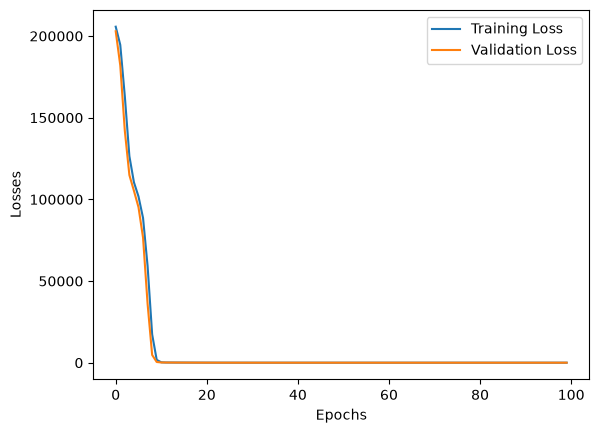

In [18]:
import matplotlib.pyplot as plt

loss_df = pd.DataFrame({
    "Training Loss": train_losses,
    "Validation Loss": val_losses
})

# plt.figure(figsize=(12,8))
plt.plot(loss_df["Training Loss"], label = "Training Loss")
plt.plot(loss_df["Validation Loss"], label = "Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Losses")

plt.legend()

### Saving & Loading model

In [19]:
model.load_state_dict(torch.load("best_model.pt"))

<All keys matched successfully>

# Evaluate our model

In [20]:
model.eval()
with torch.no_grad():
    train_preds = model(X_train_tensor)
    test_preds = model(X_test_tensor)

    train_mse_loss = criterion(train_preds, y_train_tensor)
    test_mse_loss = criterion(test_preds, y_test_tensor)

print("Training MSE:", train_mse_loss.item())
print("Testing MSE:", test_mse_loss.item())

Training MSE: 21.178434371948242
Testing MSE: 19.50274658203125


In [21]:
from sklearn.metrics import r2_score

print("r2 Score: ", r2_score(y_test, test_preds)*100,"%")

r2 Score:  93.18429294777381 %


In [22]:
predicted_df = pd.DataFrame(test_preds.numpy(), columns=["Predicted Values"])
actual_df = pd.DataFrame(y_test.values, columns=["Actual Values"])

pd.concat([predicted_df, actual_df], axis=1)

,Predicted Values,Actual Values
0,435.620300,433.27
1,437.025726,438.16
2,461.296539,458.42
3,475.906708,480.82
4,435.870087,441.41
...,...,...
1909,451.187836,456.70
1910,431.904999,438.04
1911,467.488190,467.80
1912,431.354370,437.14
